# 1. Problem Statement

## Business Problem

Climate change is an important topic in political communication. Political parties discuss climate policies using different arguments, emotions and communication styles.

Organisations such as NGOs, media monitoring teams and public-affairs departments need to understand how political actors communicate about climate change. However, manually reviewing thousands of speeches, press releases and social media posts takes considerable time.

This project develops an NLP-based system to analyse German climate-related political communication, focusing on three areas:

- **Sentiment analysis:** Identify positive, neutral and negative language.
- **Anger detection:** Identify language that expresses anger.
- **Populist language detection:** Identify anti-elite and people-centric expressions.

The aim is to support the monitoring and analysis of political communication. The system will provide analytical support and will not make political judgements about individuals or organisations.

# 2. Data Source
We use the publicly available AfD Climate Change Corpus (AfD-CCC):
https://github.com/rmemminger/afd-ccc

The published corpus includes German and European Parliament speeches, press releases and Telegram messages, among other sources. The repository reports 4,629 publicly available texts in Version 2.0. Your current code loads 3,961 records from three sources, so we should describe your dataset as a selected subset rather than the complete corpus



# 2. HIGH-LEVEL SYSTEM DESIGN

Pipeline Overview

1. Data Loading          → Download real AfD-CCC files
2. Cleaning & Filtering  → Remove very short texts, clean German text
3. Feature Extraction    → TF-IDF (simple and effective)
4. Modelling
   • Sentiment model
   • Anger model
   • Populism score (lexicon + classifier)
5. Evaluation            → Accuracy, Precision, Recall, F1
6. Analysis & Business Recommendations

# 3. Import Libraries


In [1]:
import pandas as pd
import numpy as np
import re
import requests
from io import StringIO
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

In [2]:
urls = {
    "bundestag": "https://raw.githubusercontent.com/rmemminger/afd-ccc/main/data/bt_speeches_2017-2025.csv",
    "press": "https://raw.githubusercontent.com/rmemminger/afd-ccc/main/data/press_releases_2017-2021.csv",
    "telegram": "https://raw.githubusercontent.com/rmemminger/afd-ccc/main/data/telegram_2018-2025.csv"
}

dfs = []

for source_name, url in urls.items():

    response = requests.get(url, timeout=40)
    response.raise_for_status()

    temp = pd.read_csv(StringIO(response.text))

    temp["source"] = source_name

    dfs.append(temp)

    print(source_name, ":", len(temp), "records")

df = pd.concat(dfs, ignore_index=True)

print("\nTotal records:", len(df))

df.head()

bundestag : 2284 records
press : 911 records
telegram : 766 records

Total records: 3961


,Unnamed: 0,id,author,date,text,text_tokenised,token_count,source,channel_id
0,0,sp19_4,Tino Chrupalla,2017-11-21,Aber auch die Grünen will ich nicht aus der Ve...,Aber auch die Grünen will ich nicht aus der Ve...,131,bundestag,NaN
1,1,sp19_4,Tino Chrupalla,2017-11-21,Mit gesunden Heimatmärkten hätten wir das Prob...,Mit gesunden Heimatmärkten hätten wir das Prob...,59,bundestag,NaN
2,2,sp19_9,Heiko Heßenkemper,2017-11-21,Zurück zu Siemens. Hier ist jetzt die Kraftwer...,Zurück zu Siemens Hier ist jetzt die Kraftwer...,49,bundestag,NaN
3,3,sp19_14,Marc Bernhard,2017-11-21,Stattdessen führt jedoch eine von Ihnen grünäu...,Stattdessen führt jedoch eine von Ihnen grünäu...,40,bundestag,NaN
4,4,sp19_21,Karsten Hilse,2017-11-21,Frau Präsidentin! Werte Kollegen! Offensichtli...,Frau Präsidentin Werte Kollegen Offensichtli...,127,bundestag,NaN


# 4. Data quality checks

In [3]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:")
print(df.duplicated().sum())

print("\nData sample:")
display(df.head())

Dataset shape: (3961, 9)

Column names:
['Unnamed: 0', 'id', 'author', 'date', 'text', 'text_tokenised', 'token_count', 'source', 'channel_id']

Missing values:
Unnamed: 0           0
id                 766
author             824
date                 0
text                 0
text_tokenised       0
token_count          0
source               0
channel_id        3195
dtype: int64

Duplicate records:
0

Data sample:


,Unnamed: 0,id,author,date,text,text_tokenised,token_count,source,channel_id
0,0,sp19_4,Tino Chrupalla,2017-11-21,Aber auch die Grünen will ich nicht aus der Ve...,Aber auch die Grünen will ich nicht aus der Ve...,131,bundestag,NaN
1,1,sp19_4,Tino Chrupalla,2017-11-21,Mit gesunden Heimatmärkten hätten wir das Prob...,Mit gesunden Heimatmärkten hätten wir das Prob...,59,bundestag,NaN
2,2,sp19_9,Heiko Heßenkemper,2017-11-21,Zurück zu Siemens. Hier ist jetzt die Kraftwer...,Zurück zu Siemens Hier ist jetzt die Kraftwer...,49,bundestag,NaN
3,3,sp19_14,Marc Bernhard,2017-11-21,Stattdessen führt jedoch eine von Ihnen grünäu...,Stattdessen führt jedoch eine von Ihnen grünäu...,40,bundestag,NaN
4,4,sp19_21,Karsten Hilse,2017-11-21,Frau Präsidentin! Werte Kollegen! Offensichtli...,Frau Präsidentin Werte Kollegen Offensichtli...,127,bundestag,NaN


In [4]:
df = df[["text", "source"]].copy()

df["text"] = df["text"].astype(str)

df = df.dropna(subset=["text"])

df["text"] = df["text"].str.strip()

df = df[df["text"].str.len() > 50]

df = df.drop_duplicates(subset=["text"])

df = df.reset_index(drop=True)

print("Records after cleaning:", len(df))

Records after cleaning: 3802


# 5. Text preprocessing

In [5]:
def clean_text(text):

    text = str(text).lower()

    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    text = re.sub(r"\s+", " ", text)

    return text.strip()


df["clean_text"] = df["text"].apply(clean_text)

df["word_count"] = df["clean_text"].apply(
    lambda x: len(x.split())
)

df = df[df["word_count"] >= 10].reset_index(drop=True)

print("Final records:", len(df))

display(df[["source", "text", "clean_text", "word_count"]].head())

Final records: 3799


,source,text,clean_text,word_count
0,bundestag,Aber auch die Grünen will ich nicht aus der Ve...,aber auch die grünen will ich nicht aus der ve...,129
1,bundestag,Mit gesunden Heimatmärkten hätten wir das Prob...,mit gesunden heimatmärkten hätten wir das prob...,57
2,bundestag,Zurück zu Siemens. Hier ist jetzt die Kraftwer...,zurück zu siemens. hier ist jetzt die kraftwer...,49
3,bundestag,Stattdessen führt jedoch eine von Ihnen grünäu...,stattdessen führt jedoch eine von ihnen grünäu...,40
4,bundestag,Frau Präsidentin! Werte Kollegen! Offensichtli...,frau präsidentin! werte kollegen! offensichtli...,125


# 6. Prepare reliable labels

In [6]:
annotation_sample = df.sample(
    n=min(300, len(df)),
    random_state=RANDOM_STATE
).copy()

annotation_sample["sentiment"] = ""
annotation_sample["anger"] = ""
annotation_sample["anti_elite"] = ""
annotation_sample["people_centric"] = ""

annotation_sample = annotation_sample[
    [
        "source",
        "text",
        "sentiment",
        "anger",
        "anti_elite",
        "people_centric"
    ]
]

annotation_sample.to_csv(
    "afd_manual_annotation.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Annotation file created.")

Annotation file created.


In [7]:
# 3.4 Train / Test split + Modelling 
print("\nTraining models...")

X = df["clean_text"]
y_sent = df["sentiment"]
y_anger = df["anger"]
y_pop = df["populist"]

# Safe split (no mixed types anymore)
X_train, X_test, ys_train, ys_test = train_test_split(
    X, y_sent, test_size=0.25, random_state=42, stratify=y_sent
)
_, _, ya_train, ya_test = train_test_split(
    X, y_anger, test_size=0.25, random_state=42, stratify=y_anger
)
_, _, yp_train, yp_test = train_test_split(
    X, y_pop, test_size=0.25, random_state=42, stratify=y_pop
)

# Simple and reliable pipelines
sent_pipe = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=2500, ngram_range=(1, 2), min_df=3)),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
])

anger_pipe = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=2500, ngram_range=(1, 2), min_df=3)),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
])

pop_pipe = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=2500, ngram_range=(1, 2), min_df=3)),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
])

sent_pipe.fit(X_train, ys_train)
anger_pipe.fit(X_train, ya_train)
pop_pipe.fit(X_train, yp_train)

print("Models trained successfully.")


Training models...
Models trained successfully.


# 4. EVALUATION



EVALUATION RESULTS

--- Sentiment Classification ---
              precision    recall  f1-score   support

    negative       0.54      0.65      0.59       164
     neutral       0.93      0.89      0.91       827

    accuracy                           0.85       991
   macro avg       0.73      0.77      0.75       991
weighted avg       0.86      0.85      0.85       991

Accuracy: 0.85

--- Anger Detection ---
              precision    recall  f1-score   support

           0       0.83      0.73      0.78       827
           1       0.16      0.26      0.20       164

    accuracy                           0.65       991
   macro avg       0.50      0.49      0.49       991
weighted avg       0.72      0.65      0.68       991

Accuracy: 0.65

--- Populism Detection ---
              precision    recall  f1-score   support

           0       0.71      0.64      0.67       693
           1       0.32      0.40      0.36       298

    accuracy                           0.57  

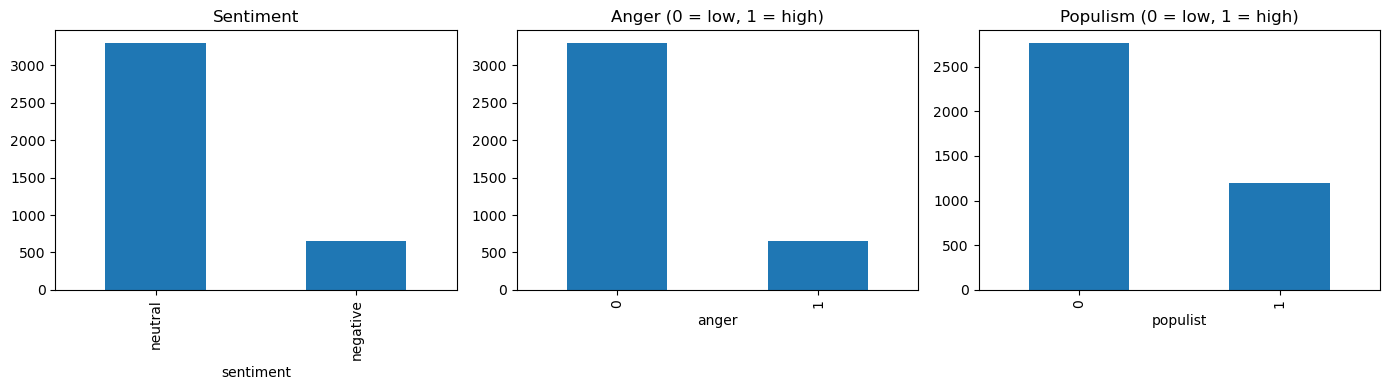

In [8]:

print("\n" + "="*60)
print("EVALUATION RESULTS")
print("="*60)

print("\n--- Sentiment Classification ---")
pred_s = sent_pipe.predict(X_test)
print(classification_report(ys_test, pred_s))
print("Accuracy:", round(accuracy_score(ys_test, pred_s), 3))

print("\n--- Anger Detection ---")
pred_a = anger_pipe.predict(X_test)
print(classification_report(ya_test, pred_a))
print("Accuracy:", round(accuracy_score(ya_test, pred_a), 3))

print("\n--- Populism Detection ---")
pred_p = pop_pipe.predict(X_test)
print(classification_report(yp_test, pred_p))
print("Accuracy:", round(accuracy_score(yp_test, pred_p), 3))

# Visualisation
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
df["sentiment"].value_counts().plot(kind="bar", ax=axes[0], title="Sentiment")
df["anger"].value_counts().plot(kind="bar", ax=axes[1], title="Anger (0 = low, 1 = high)")
df["populist"].value_counts().plot(kind="bar", ax=axes[2], title="Populism (0 = low, 1 = high)")
plt.tight_layout()
plt.show()